# Spare-Part Demand Forecasting - NewX Services (Ref PM-PR-0027)
**Goal:** forecast spare-part demand per part x service centre x week, 4 weeks ahead, and beat a naive baseline by >= 20% on overstock and stockout events.

**Flow:** load -> clean -> EDA -> weekly panel -> features -> model vs baselines -> importance -> forecast -> recommendations.
Logic lives in `src/pipeline.py` (also used by `run.py` and the Streamlit app). Run this notebook from the repo root or `notebooks/`.

**Standalone:** the next cells install packages and write `src/pipeline.py` (the full pipeline) and `report.py` (PDF builder) so this notebook runs alone in Colab or Jupyter.
**Data access:** if `data/raw_service_data.csv` exists it is used. Otherwise the notebook asks for the MySQL host/user/password. No credentials are stored in this notebook.

In [1]:
!pip install -q lightgbm sqlalchemy pymysql reportlab statsmodels
!pip install -q prophet
import os; os.makedirs("src", exist_ok=True)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
%%writefile src/pipeline.py
"""Spare-part demand forecasting: load -> clean -> weekly panel -> features -> LightGBM -> 4-week forecast.

Direct multi-step design: every feature uses data at least H weeks old, so one model
forecasts all H weeks ahead without recursive prediction and without look-ahead leakage.
"""
import json
import os
import re
from pathlib import Path

import joblib
import lightgbm as lgb
import numpy as np
import pandas as pd

H = 4  # forecast horizon (weeks) and minimum lag
TEST_WEEKS = 12  # last N observed weeks held out for evaluation
RAW_COLS = {
    "Invoice Date": "invoice_date",
    "Job Card Date": "job_card_date",
    "Business Partner Name": "partner",
    "Vehicle No.": "vehicle_no",
    "Vehicle Model": "vehicle_model",
    "Current KM Reading": "km",
    "INVOICE LINE TEXT": "line_text",
}
# services, labour and supplies: not spare parts. Edit to taste; clean() flags them, weekly_panel() drops them.
NON_PART = r"service|consumable|polish|labou?r|wash|lubrication|charge|inspection|alignment|balancing|fitting|discount|round off|check ?up|cleaning"
FEATURES = [
    "lag_4", "lag_5", "lag_6", "lag_8", "lag_12",
    "roll_mean_4", "roll_mean_8", "roll_mean_13", "roll_std_8",
    "km_lag", "km_bin", "jobs_lag",
    "week_of_year", "month", "woy_sin", "woy_cos",
    "item_c", "centre_c",
]


# ---------- load / clean ----------
def load_raw(csv=None, cache="data/raw_service_data.csv"):
    """MySQL if DB_HOST is set (credentials from env, never in code), else a CSV."""
    if os.getenv("DB_HOST"):
        from sqlalchemy import create_engine
        from sqlalchemy.engine import URL

        url = URL.create(
            "mysql+pymysql",
            username=os.environ["DB_USER"].strip(),
            password=os.environ["DB_PASSWORD"].strip(),
            host=os.environ["DB_HOST"].strip(),
            port=int(os.getenv("DB_PORT", 3306)),
            database=os.environ["DB_NAME"],
        )
        df = pd.read_sql(f"SELECT * FROM {os.getenv('DB_TABLE', 'service_data')}", create_engine(url))
        Path(cache).parent.mkdir(parents=True, exist_ok=True)
        df.to_csv(cache, index=False)
        return df
    path = csv or cache
    if not Path(path).exists():
        raise FileNotFoundError(f"{path} not found. Set DB_* env vars (see .env.example) or pass a CSV.")
    return pd.read_csv(path)


def norm_item(text):
    """'OIL FILTER - 4521' -> 'oil filter'. Digits/punctuation dropped, first 4 words kept."""
    return " ".join(re.sub(r"[^a-z ]", " ", str(text).lower()).split()[:4])


def _dates(s):
    """dd-mm-yy text (the DB format) first; ISO / real datetimes otherwise. dayfirst=True would corrupt ISO dates."""
    if pd.api.types.is_datetime64_any_dtype(s):
        return s
    d = pd.to_datetime(s, format="%d-%m-%y", errors="coerce")
    return d if d.isna().mean() <= 0.5 else pd.to_datetime(s, errors="coerce")


def clean(df):
    # match columns ignoring case, spaces, dots and underscores ("Invoice Date" == "invoice_date")
    key = lambda c: re.sub(r"[^a-z0-9]", "", str(c).lower())
    want = {key(k): v for k, v in RAW_COLS.items()}
    df = df.rename(columns={c: want[key(c)] for c in df.columns if key(c) in want})
    missing = set(RAW_COLS.values()) - set(df.columns)
    if missing:
        raise KeyError(f"columns not found: {sorted(missing)}. Columns present: {list(df.columns)}")
    for c in ("invoice_date", "job_card_date"):
        df[c] = _dates(df[c])
    df["invoice_date"] = df["invoice_date"].fillna(df["job_card_date"])
    df["km"] = pd.to_numeric(df["km"].astype(str).str.replace(",", ""), errors="coerce")
    df = df.dropna(subset=["invoice_date", "line_text"]).copy()
    df["item"] = df["line_text"].map(norm_item)
    # repeated identical lines are kept: there is no quantity column, a repeat can mean qty > 1
    df = df[df["item"] != ""].reset_index(drop=True)
    df["is_part"] = ~df["item"].str.contains(NON_PART, regex=True)
    return df


# ---------- weekly panel ----------
def weekly_panel(df, centre_col=None, top_items=25, top_centres=5):
    """Full item x centre x week grid. demand = invoice lines per week (no qty column exists).

    centre_col: column used as 'service centre' ('partner' is the only proxy in the data).
    Returns (panel, last_observed_week). The panel includes H future weeks with demand = NaN.
    """
    df = df.copy()
    df["week"] = df["invoice_date"].dt.normalize() - pd.to_timedelta(df["invoice_date"].dt.weekday, unit="D")
    d0, d1 = df["invoice_date"].min().normalize(), df["invoice_date"].max().normalize()
    first = d0 - pd.Timedelta(days=d0.weekday())
    if d0 != first:
        first += pd.Timedelta(weeks=1)  # drop partial first week
    last = d1 - pd.Timedelta(days=d1.weekday())
    if d1 != last + pd.Timedelta(days=6):
        last -= pd.Timedelta(weeks=1)  # drop partial last week
    df = df[(df["week"] >= first) & (df["week"] <= last)]
    jobs = df.groupby("week").size()  # shop-wide volume, all lines
    if "is_part" in df:
        df = df[df["is_part"]]

    df["centre"] = df[centre_col].astype(str).str.strip() if centre_col else "ALL"
    df = df[df["item"].isin(df["item"].value_counts().head(top_items).index)]
    df = df[df["centre"].isin(df["centre"].value_counts().head(top_centres).index)]

    g = df.groupby(["item", "centre", "week"]).agg(demand=("item", "size"), km_mean=("km", "mean")).reset_index()
    weeks = pd.DataFrame({"week": pd.date_range(first, last + pd.Timedelta(weeks=H), freq="7D")})
    p = g[["item", "centre"]].drop_duplicates().merge(weeks, how="cross").merge(g, on=["item", "centre", "week"], how="left")
    p["demand"] = np.where(p["week"] <= last, p["demand"].fillna(0), np.nan)
    p["jobs"] = p["week"].map(jobs)
    return p.sort_values(["item", "centre", "week"]).reset_index(drop=True), last


# ---------- features ----------
def add_features(p):
    p = p.copy()
    g = p.groupby(["item", "centre"])
    for k in (H, H + 1, H + 2, H + 4, H + 8):
        p[f"lag_{k}"] = g["demand"].shift(k)
    for w in (4, 8, 13):
        p[f"roll_mean_{w}"] = g["demand"].transform(lambda s, w=w: s.shift(H).rolling(w, min_periods=1).mean())
    p["roll_std_8"] = g["demand"].transform(lambda s: s.shift(H).rolling(8, min_periods=2).std())
    p["km_lag"] = g["km_mean"].transform(lambda s: s.shift(H).ffill())
    p["km_bin"] = (p["km_lag"] // 10000).clip(upper=15)  # 10k-km service-interval bins
    wk_jobs = p.groupby("week")["jobs"].first().sort_index().shift(H)
    p["jobs_lag"] = p["week"].map(wk_jobs)
    p["week_of_year"] = p["week"].dt.isocalendar().week.astype(int)
    p["month"] = p["week"].dt.month
    p["woy_sin"] = np.sin(2 * np.pi * p["week_of_year"] / 52)
    p["woy_cos"] = np.cos(2 * np.pi * p["week_of_year"] / 52)
    p["item_c"] = p["item"].astype("category")
    p["centre_c"] = p["centre"].astype("category")
    return p


def split(p, last):
    """Time-based split. Returns (train, test, future)."""
    obs = p[p["demand"].notna()].dropna(subset=["lag_4"])
    cut = last - pd.Timedelta(weeks=TEST_WEEKS - 1)
    return obs[obs["week"] < cut], obs[obs["week"] >= cut], p[p["week"] > last]


# ---------- model / evaluation ----------
def fit(train):
    m = lgb.LGBMRegressor(
        objective="poisson", n_estimators=400, learning_rate=0.03, num_leaves=15,
        min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=0, verbose=-1,
    )
    return m.fit(train[FEATURES], train["demand"])


def evaluate(y, pred):
    """Order quantity = rounded forecast. overstock: ordered > needed; stockout: ordered < needed."""
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    order = np.rint(pred)
    over, under = np.maximum(order - y, 0), np.maximum(y - order, 0)
    nz = y > 0
    return {
        "MAE": float(np.abs(y - pred).mean()),
        "RMSE": float(np.sqrt(((y - pred) ** 2).mean())),
        "WAPE": float(np.abs(y - pred).sum() / max(y.sum(), 1e-9)),
        "MAPE_nonzero": float((np.abs(y - pred)[nz] / y[nz]).mean()) if nz.any() else float("nan"),
        "overstock_events": int((over > 0).sum()),
        "stockout_events": int((under > 0).sum()),
        "overstock_units": float(over.sum()),
        "stockout_units": float(under.sum()),
    }


def compare(test, pred):
    rows = {
        "naive_lag4": evaluate(test["demand"], test["lag_4"]),  # same info set as the model
        "moving_avg_4": evaluate(test["demand"], test["roll_mean_4"]),
        "lightgbm": evaluate(test["demand"], pred),
    }
    tab = pd.DataFrame(rows).T
    n, m = tab.loc["naive_lag4"], tab.loc["lightgbm"]
    gain = {k: float(1 - m[k] / n[k]) if n[k] else float("nan") for k in
            ("overstock_events", "stockout_events", "overstock_units", "stockout_units")}
    return tab, gain


# ---------- time-series cross-validation ----------
def cv(obs, n_splits=5, test_weeks=8, min_train=26):
    """Rolling-origin CV by week (sklearn TimeSeriesSplit on the sorted weeks). obs = observed rows with lags."""
    from sklearn.model_selection import TimeSeriesSplit

    weeks = np.sort(obs["week"].unique())
    n = min(n_splits, (len(weeks) - min_train) // test_weeks)
    if n < 2:
        return pd.DataFrame()
    rows = []
    for tr, te in TimeSeriesSplit(n_splits=n, test_size=test_weeks).split(weeks):
        a, b = obs[obs["week"].isin(weeks[tr])], obs[obs["week"].isin(weeks[te])]
        t, g = compare(b, fit(a).predict(b[FEATURES]))
        rows.append({"test_from": str(weeks[te][0])[:10], "WAPE_lightgbm": t.loc["lightgbm", "WAPE"],
                     "WAPE_naive": t.loc["naive_lag4", "WAPE"], "MAE_lightgbm": t.loc["lightgbm", "MAE"],
                     **{f"gain_{k}": v for k, v in g.items()}})
    return pd.DataFrame(rows)


# ---------- classical models (ARIMA with Fourier seasonality, Prophet) on the top series ----------
def _arima(y, fut_weeks):
    from statsmodels.tsa.statespace.sarimax import SARIMAX

    def fourier(w):
        woy = pd.Series(w).dt.isocalendar().week.astype(int).to_numpy()
        return np.column_stack([f(2 * np.pi * k * woy / 52) for k in (1, 2) for f in (np.sin, np.cos)])

    ex = len(y) >= 60  # annual terms need enough history
    try:
        m = SARIMAX(y.to_numpy(float), exog=fourier(y.index) if ex else None, order=(1, 0, 1), trend="c").fit(disp=False)
        return np.clip(m.forecast(len(fut_weeks), exog=fourier(fut_weeks) if ex else None), 0, None)
    except Exception:
        return np.repeat(y.tail(4).mean(), len(fut_weeks))


def _prophet(y, fut_weeks):
    import logging
    from prophet import Prophet

    logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
    m = Prophet(weekly_seasonality=False, daily_seasonality=False, yearly_seasonality=len(y) >= 104)
    m.fit(pd.DataFrame({"ds": y.index, "y": y.to_numpy(float)}))
    return np.clip(m.predict(pd.DataFrame({"ds": fut_weeks}))["yhat"].to_numpy(), 0, None)


def classical_compare(p, last, test_pred, top=8):
    """4-week-ahead ARIMA/Prophet vs LightGBM and naive on the top series (centres summed), rolling origins over the test window.
    test_pred: DataFrame item, centre, week, demand, lag_4, pred."""
    hist = p[p["demand"].notna()].groupby(["item", "week"])["demand"].sum().unstack(0).fillna(0)
    items = hist.sum().sort_values(ascending=False).head(top).index
    start = last - pd.Timedelta(weeks=TEST_WEEKS - 1)
    models = {"arima_fourier": _arima}
    try:
        import prophet  # noqa: F401
        models["prophet"] = _prophet
    except Exception:
        pass
    preds = {m: [] for m in models}
    for item in items:
        for o in pd.date_range(start, last, freq=f"{H * 7}D"):
            fw = pd.date_range(o, periods=H, freq="7D")
            y = hist.loc[hist.index < o, item]
            for name, f in models.items():
                preds[name].append(pd.DataFrame({"item": item, "week": fw, name: f(y, fw)}))
    tp = test_pred[test_pred["item"].isin(items)].groupby(["item", "week"])[["demand", "lag_4", "pred"]].sum().reset_index()
    for name, parts in preds.items():
        tp = tp.merge(pd.concat(parts), on=["item", "week"], how="left")
    tp = tp[tp["week"] <= last].dropna()
    cols = {"naive_lag4": "lag_4", "lightgbm": "pred", **{m: m for m in models}}
    rows = {k: evaluate(tp["demand"], tp[c]) for k, c in cols.items()}
    return pd.DataFrame(rows).T[["MAE", "RMSE", "WAPE"]], tp


# ---------- plain-language recommendations from the real results ----------
def recommendations(out="outputs"):
    m = json.loads(Path(f"{out}/metrics.json").read_text())
    acc = pd.read_csv(f"{out}/item_accuracy.csv")
    fc = pd.read_csv(f"{out}/forecast.csv")
    hist = pd.read_csv(f"{out}/weekly_history.csv", parse_dates=["week"])
    g, t = m["improvement_vs_naive"], m["table"]["lightgbm"]
    r = []
    top = fc.groupby("part_name")["predicted_demand"].sum().sort_values(ascending=False).head(5)
    r.append("Order first: " + ", ".join(f"{k} (~{v:.0f} lines in the next {m['horizon_weeks']} weeks)" for k, v in top.items()) + ".")
    if m["target_met"]:
        r.append(f"The model cut overstock events by {g['overstock_events']:.0%} and stockout events by {g['stockout_events']:.0%} versus the naive baseline: the 20% target is met on the hold-out weeks.")
    else:
        r.append(f"Target not met: events fell {g['overstock_events']:.0%} (overstock) and {g['stockout_events']:.0%} (stockout) versus naive, below 20% on at least one. "
                 f"Units fell {g['overstock_units']:.0%} and {g['stockout_units']:.0%}, so use the model for sizing orders and judge it on units, not event counts.")
    if t["stockout_units"] > t["overstock_units"]:
        r.append(f"The model under-orders more than it over-orders ({t['stockout_units']:.0f} short vs {t['overstock_units']:.0f} excess units on hold-out): add a safety-stock buffer on fast-moving parts.")
    else:
        r.append(f"The model over-orders more than it under-orders ({t['overstock_units']:.0f} excess vs {t['stockout_units']:.0f} short units on hold-out): trim order quantities on slow parts before adding buffer.")
    bad = acc[(acc["actual"] >= 20) & (acc["WAPE_model"] > 0.6)].sort_values("actual", ascending=False).head(5)["item"].tolist()
    if bad:
        r.append("Keep manual review for hard-to-forecast parts (hold-out WAPE above 60%): " + ", ".join(bad) + ".")
    if m["n_weeks"] >= 52:
        mo = hist.assign(month=hist["week"].dt.month).groupby(["item", "month"])["demand"].mean().unstack()
        ratio = (mo.max(axis=1) / mo.mean(axis=1)).sort_values(ascending=False)
        seas = [f"{i} (peak month {int(mo.loc[i].idxmax())})" for i in ratio[ratio >= 1.5].head(4).index]
        if seas:
            r.append("Seasonal parts: stock up the month before the peak for " + ", ".join(seas) + ".")
    else:
        r.append(f"Only {m['n_weeks']} weeks of history: annual seasonality cannot be learned yet. Re-train when a full year or more is available.")
    r.append("Close the data gaps: record quantity, part number and service-centre ID on every invoice line. Demand is currently a count of lines, and services and parts share one text field.")
    return r


# ---------- end to end ----------
def run(df, centre_col=None, out="outputs", models="models", top_items=25, top_centres=5):
    Path(out).mkdir(exist_ok=True, parents=True)
    Path(models).mkdir(exist_ok=True, parents=True)
    panel, last = weekly_panel(df, centre_col, top_items, top_centres)
    p = add_features(panel)
    train, test, future = split(p, last)

    tab, gain = compare(test, fit(train).predict(test[FEATURES]))
    final = fit(pd.concat([train, test]))  # refit on all observed data for the real forecast
    joblib.dump({"model": final, "features": FEATURES, "horizon": H}, f"{models}/demand_model.joblib")

    fc = future[["item", "centre", "week"]].copy()
    fc["predicted_demand"] = np.clip(final.predict(future[FEATURES]), 0, None).round(2)
    fc.rename(columns={"item": "part_name", "centre": "service_centre"}).to_csv(f"{out}/forecast.csv", index=False)

    tp = test[["item", "centre", "week", "demand", "lag_4"]].copy()
    tp["pred"] = fit(train).predict(test[FEATURES])
    tp.to_csv(f"{out}/test_predictions.csv", index=False)
    tp.groupby("item").apply(lambda d: pd.Series({
        "actual": d["demand"].sum(),
        "WAPE_model": (d["demand"] - d["pred"]).abs().sum() / max(d["demand"].sum(), 1),
        "WAPE_naive": (d["demand"] - d["lag_4"]).abs().sum() / max(d["demand"].sum(), 1)}), include_groups=False) \
        .reset_index().to_csv(f"{out}/item_accuracy.csv", index=False)
    cvt = cv(pd.concat([train, test]))
    cmp_tab, _ = classical_compare(p, last, tp)
    cmp_tab.to_csv(f"{out}/model_comparison.csv")
    cvt.to_csv(f"{out}/cv_folds.csv", index=False)
    p[p["demand"].notna()][["item", "centre", "week", "demand"]].to_csv(f"{out}/weekly_history.csv", index=False)
    pd.DataFrame({"feature": FEATURES, "gain": final.booster_.feature_importance("gain")}) \
        .sort_values("gain", ascending=False).to_csv(f"{out}/feature_importance.csv", index=False)

    metrics = {
        "horizon_weeks": H, "test_weeks": TEST_WEEKS, "last_observed_week": str(last.date()),
        "n_items": int(p["item"].nunique()), "n_centres": int(p["centre"].nunique()),
        "n_train_rows": len(train), "n_test_rows": len(test),
        "table": tab.to_dict("index"), "improvement_vs_naive": gain,
        "target_met": bool(all(v >= 0.20 for k, v in gain.items() if k.endswith("events"))),
        "n_weeks": int(p.loc[p["demand"].notna(), "week"].nunique()),
        "cv_mean": cvt.drop(columns="test_from").mean().to_dict() if len(cvt) else {},
        "cv_std": cvt.drop(columns="test_from").std().to_dict() if len(cvt) else {},
        "cv_folds": len(cvt),
        "model_comparison": cmp_tab.to_dict("index"),
    }
    Path(f"{out}/metrics.json").write_text(json.dumps(metrics, indent=2))
    metrics["recommendations"] = recommendations(out)
    Path(f"{out}/metrics.json").write_text(json.dumps(metrics, indent=2))
    return metrics


Writing src/pipeline.py


In [3]:
%%writefile report.py
"""python report.py  -> outputs/project_report.pdf (every number comes from outputs/)"""
import json

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import cm
from reportlab.platypus import Image, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

m = json.load(open("outputs/metrics.json"))
tp = pd.read_csv("outputs/test_predictions.csv", parse_dates=["week"])
fi = pd.read_csv("outputs/feature_importance.csv").head(8)
cmp_ = pd.DataFrame(m["model_comparison"]).T
imp = m["improvement_vs_naive"]

wk = tp.groupby("week")[["demand", "lag_4", "pred"]].sum()
ax = wk.rename(columns={"demand": "actual", "lag_4": "naive (lag 4)", "pred": "LightGBM"}).plot(figsize=(7, 3))
ax.set_ylabel("invoice lines / week (modelled parts)")
plt.tight_layout()
plt.savefig("outputs/test_chart.png", dpi=150)

S = getSampleStyleSheet()
P = lambda t, s="BodyText": Paragraph(t, S[s])


def table(rows):
    t = Table(rows, repeatRows=1)
    t.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey), ("GRID", (0, 0), (-1, -1), 0.3, colors.grey),
                           ("FONTSIZE", (0, 0), (-1, -1), 8)]))
    return t


main = [["model", "MAE", "RMSE", "WAPE", "overstock ev.", "stockout ev.", "overstock u.", "stockout u."]]
for k, v in m["table"].items():
    main.append([k] + [f"{v[c]:.3f}" for c in ("MAE", "RMSE", "WAPE")] + [f"{v[c]:.0f}" for c in
                ("overstock_events", "stockout_events", "overstock_units", "stockout_units")])
second = [["model (top 8 parts, summed)", "MAE", "RMSE", "WAPE"]] + [[k] + [f"{v[c]:.3f}" for c in ("MAE", "RMSE", "WAPE")] for k, v in m["model_comparison"].items()]
best = cmp_["WAPE"].idxmin()
met = "MET" if m["target_met"] else "NOT met"

story = [
    P("Spare-Part Demand Forecasting - NewX Services", "Title"),
    P("1. Objective", "Heading2"),
    P("Forecast weekly spare-part demand per part and service centre, 4 weeks ahead, to support a just-in-time inventory policy. "
      "Target: at least 20% fewer overstock and stockout events than a naive baseline."),
    P("2. Data and method", "Heading2"),
    P(f"Source: service invoice lines (MySQL project_service_data.service_data), {m['n_weeks']} full weeks. Part names are parsed from INVOICE LINE TEXT "
      f"(lower-case, digits removed, first 4 words). Service, labour and supply lines (e.g. general service, consumables, polish) are excluded. "
      f"The {m['n_items']} most frequent parts are modelled across {m['n_centres']} centre group(s). Demand is the weekly count of invoice lines; the data has no quantity column. "
      f"Features use only data at least {m['horizon_weeks']} weeks old: lags, rolling mean/std, last-known odometer and 10,000-km bin, shop-wide job volume, week-of-year seasonality. "
      "Model: LightGBM, Poisson loss, one direct model for all horizons. "
      f"Hold-out: last {m['test_weeks']} observed weeks. Baselines: naive (demand 4 weeks ago) and 4-week moving average. "
      "Order quantity = rounded forecast; overstock = ordered above need, stockout = ordered below need."),
    P("3. Results on the hold-out weeks", "Heading2"),
    table(main),
    Spacer(1, 6),
    P(f"Reduction vs naive: overstock events {imp['overstock_events']:.1%}, stockout events {imp['stockout_events']:.1%}, "
      f"overstock units {imp['overstock_units']:.1%}, stockout units {imp['stockout_units']:.1%}. The 20% event target is <b>{met}</b>."),
    Image("outputs/test_chart.png", width=16 * cm, height=6.9 * cm),
    P("Top features by gain: " + ", ".join(fi["feature"]) + "."),
    P("4. Model comparison and cross-validation", "Heading2"),
    table(second),
    Spacer(1, 6),
    P(f"ARIMA (with annual Fourier terms) and Prophet were run on the top parts with rolling 4-week origins over the hold-out. Lowest WAPE: <b>{best}</b>. "
      "LightGBM is the deployed model because it forecasts every part and centre with one model and uses odometer and shop-volume features; "
      "the classical models are per-series and cover only the top parts."),
    P((f"Rolling-origin CV ({m['cv_folds']} folds, sklearn TimeSeriesSplit): LightGBM WAPE {m['cv_mean']['WAPE_lightgbm']:.3f} +/- {m['cv_std']['WAPE_lightgbm']:.3f} "
       f"vs naive {m['cv_mean']['WAPE_naive']:.3f} +/- {m['cv_std']['WAPE_naive']:.3f}. Mean reduction in overstock units {m['cv_mean']['gain_overstock_units']:.1%}, "
       f"stockout units {m['cv_mean']['gain_stockout_units']:.1%}.") if m["cv_folds"] else "Cross-validation skipped: not enough weeks of history."),
    P("5. Business recommendations", "Heading2"),
    *[P(f"{i}. {r}") for i, r in enumerate(m["recommendations"], 1)],
    P("6. Limitations", "Heading2"),
    P("Demand counts invoice lines, not units. No service-centre column exists, so the centre dimension is a proxy or a single group. "
      "Part names come from free text and may merge or split real parts. Intermittent low-volume parts are inherently noisy; MAPE is reported only on non-zero weeks (see metrics.json). "
      "LSTM was not run: with this few weekly points per series a neural sequence model is unlikely to beat gradient boosting and adds heavy dependencies."),
]
SimpleDocTemplate("outputs/project_report.pdf", pagesize=A4).build(story)
print("outputs/project_report.pdf")


Writing report.py


In [4]:
import os, getpass
os.makedirs("src", exist_ok=True); open("src/__init__.py", "a").close()
if not os.path.exists("data/raw_service_data.csv") and not os.getenv("DB_HOST"):
    os.environ.update(DB_HOST=input("DB host: "), DB_PORT="3306", DB_NAME="project_service_data", DB_TABLE="service_data",
                      DB_USER=input("DB user: "), DB_PASSWORD=getpass.getpass("DB password: "))

DB host: 18.136.157.135
DB user: dm_usdata_sql
DB password: ··········


In [5]:
import os, sys, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import pipeline as P
sns.set_theme(style="whitegrid")

CENTRE_COL = None      # the table has no service-centre column. Set "partner" to use Business Partner Name as a proxy.
TOP_ITEMS, TOP_CENTRES = 25, 5

## 1. Load and clean

In [6]:
raw = P.load_raw()
print(raw.shape); raw.head()

(28482, 7)


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,30-05-17,30-05-17,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL


In [7]:
df = P.clean(raw)
print(f"{len(raw)} raw rows -> {len(df)} after cleaning")
print(df.isna().mean().round(3).to_string())
df[["invoice_date","vehicle_model","km","line_text","item"]].head(10)

28482 raw rows -> 28448 after cleaning
invoice_date     0.0
job_card_date    0.0
partner          0.0
vehicle_no       0.0
vehicle_model    0.0
km               0.0
line_text        0.0
item             0.0
is_part          0.0


,invoice_date,vehicle_model,km,line_text,item
0,2017-05-30,BAJAJ AVENGER STREET 220,50000,ENGINE OIL,engine oil
1,2017-06-02,BAJAJ PULSAR NS 200,758,ENGINE OIL,engine oil
2,2017-06-02,BAJAJ PULSAR NS 200,758,POLISH,polish
3,2017-06-02,BAJAJ PULSAR NS 200,758,CONSUMABLES,consumables
4,2017-06-02,BAJAJ PULSAR NS 200,758,COOLANT OIL,coolant oil
5,2017-06-02,BAJAJ PULSAR NS 200,758,CHAIN LUBRICATION,chain lubrication
6,2017-06-02,BAJAJ PULSAR NS 200,758,4 WAY SWITCH,way switch
7,2017-05-31,BAJAJ PLATINA,3717,ENGINE OIL,engine oil
8,2017-05-31,BAJAJ PLATINA,3717,3M OIL,m oil
9,2017-05-31,BAJAJ PLATINA,3717,CHAIN LUBRICATION,chain lubrication


## 2. EDA

**Non-part lines.** Service, labour and supply lines are flagged (`NON_PART` regex in the pipeline) and excluded from the forecast. Check the lists: edit `NON_PART` if a real part is excluded or a service slips through.

In [8]:
print("excluded as non-parts:"); display(df[~df.is_part].item.value_counts().head(15))
print("kept as parts:"); display(df[df.is_part].item.value_counts().head(25))

excluded as non-parts:


,count
item,
chain lubrication,3441
general service,2142
consumables,1595
polish,1245
air filter checkup,467
labour,131
washing,52
engine labour,49
tank cleaning,20


kept as parts:


,count
item,
engine oil,3802
air filter,1715
m oil,1628
disc oil,991
brake shoe,965
oil filter,821
disc pad,575
wheel rubber,521
spark plug,421


In [9]:
print("date range:", df.invoice_date.min().date(), "->", df.invoice_date.max().date())
print("vehicles:", df.vehicle_no.nunique(), "| models:", df.vehicle_model.nunique(), "| partners:", df.partner.nunique(), "| distinct items:", df.item.nunique())
df.km.describe().round(0)

date range: 2017-05-30 -> 2019-01-06
vehicles: 846 | models: 28 | partners: 1010 | distinct items: 489


,km
count,28448.0
mean,19338.0
std,25221.0
min,0.0
25%,3988.0
50%,12393.0
75%,27905.0
max,610112.0


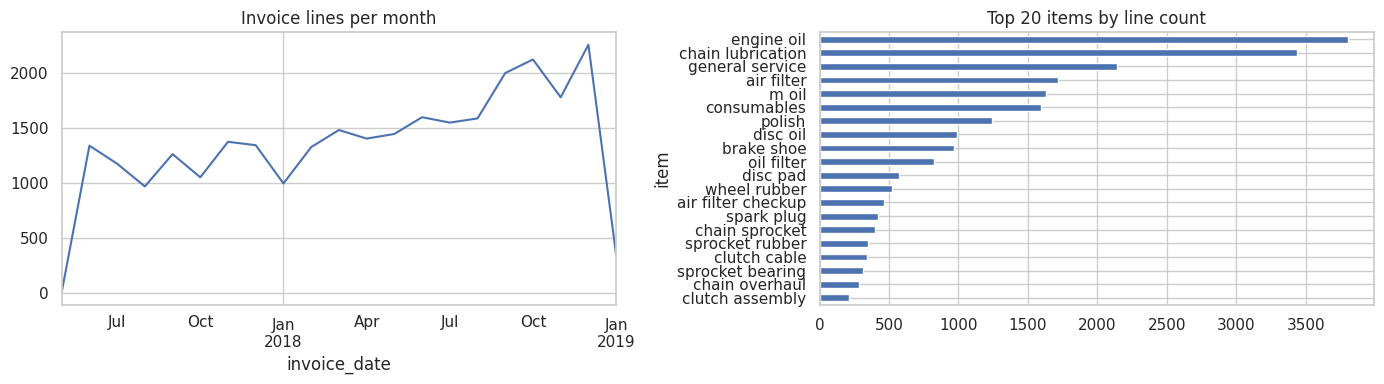

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.set_index("invoice_date").resample("MS").size().plot(ax=ax[0], title="Invoice lines per month")
df.item.value_counts().head(20).sort_values().plot.barh(ax=ax[1], title="Top 20 items by line count")
plt.tight_layout()

**Seasonality** - share of each top item's lines by calendar month (a flat row = no seasonality).

Text(0.5, 1.0, 'Monthly share of demand by item')

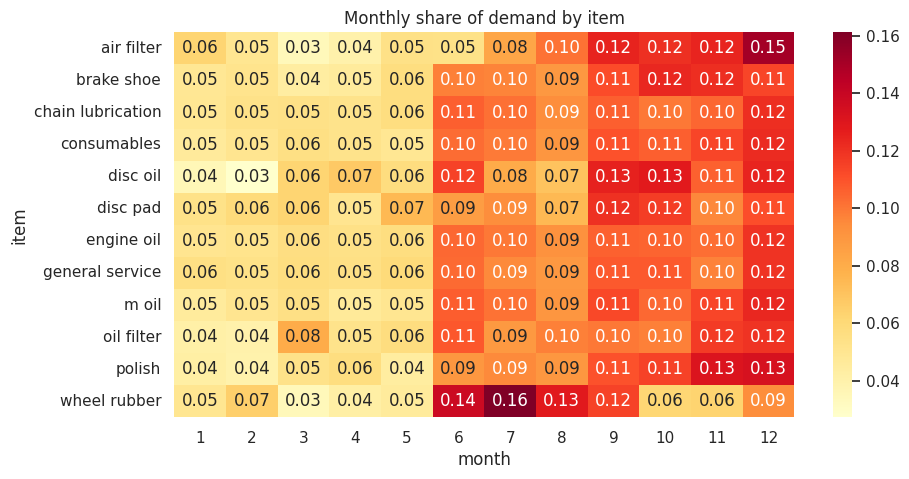

In [11]:
top = df.item.value_counts().head(12).index
s = df[df.item.isin(top)].assign(month=lambda d: d.invoice_date.dt.month)
sm = pd.crosstab(s.item, s.month, normalize="index")
plt.figure(figsize=(10, 5)); sns.heatmap(sm, cmap="YlOrRd", annot=True, fmt=".2f"); plt.title("Monthly share of demand by item")

**Demand by vehicle model and odometer band** (10,000-km service-interval bins).

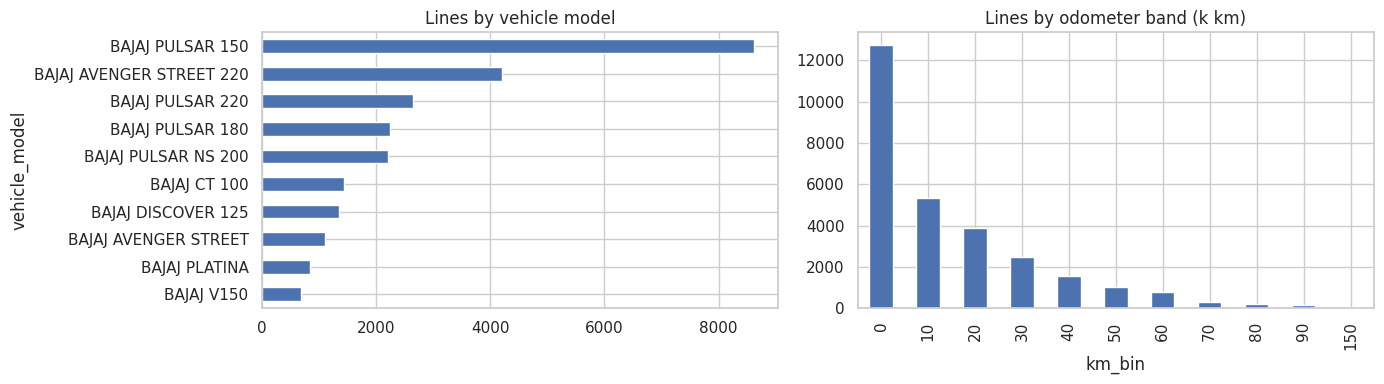

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.vehicle_model.value_counts().head(10).sort_values().plot.barh(ax=ax[0], title="Lines by vehicle model")
df.assign(km_bin=(df.km // 10000).clip(upper=15) * 10).groupby("km_bin").size().plot.bar(ax=ax[1], title="Lines by odometer band (k km)")
plt.tight_layout()

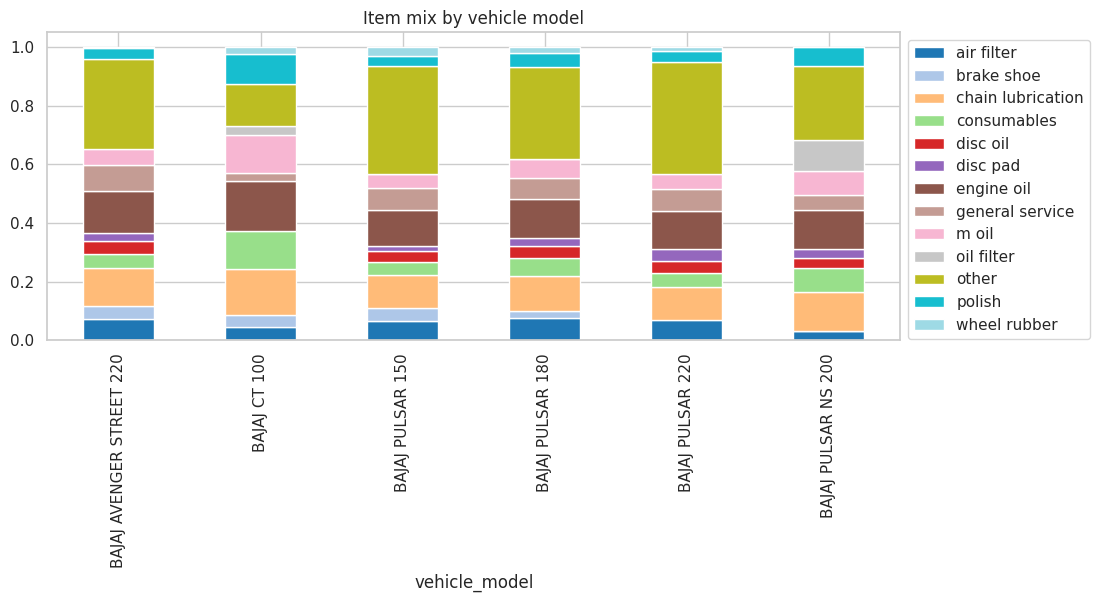

In [13]:
topm = df.vehicle_model.value_counts().head(6).index
ct = pd.crosstab(df[df.vehicle_model.isin(topm)].vehicle_model, df[df.vehicle_model.isin(topm)].item.where(lambda s: s.isin(top), "other"), normalize="index")
ct.plot.bar(stacked=True, figsize=(11, 4), colormap="tab20", title="Item mix by vehicle model").legend(bbox_to_anchor=(1, 1))

## 3. Weekly panel (item x centre x week)
Demand = invoice lines per week: there is no quantity column. Partial first/last weeks are dropped; missing weeks are zeros.

last observed full week: 2018-12-31 | series: 25
zero-demand share (intermittency): 0.194


<Axes: title={'center': 'Total weekly demand, modelled items'}, xlabel='week'>

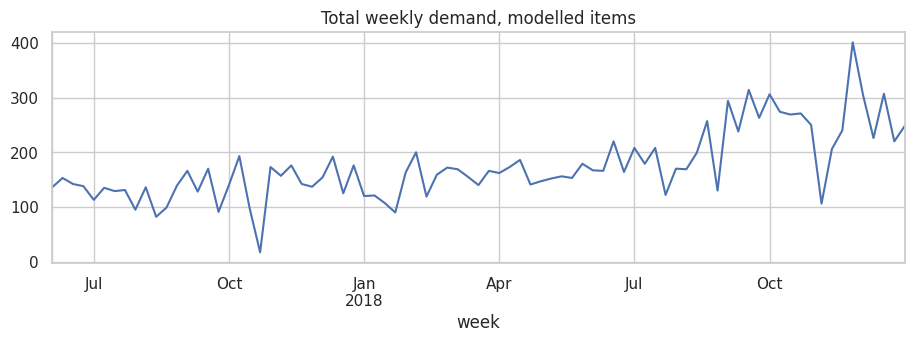

In [14]:
panel, last = P.weekly_panel(df, CENTRE_COL, TOP_ITEMS, TOP_CENTRES)
print("last observed full week:", last.date(), "| series:", panel[["item","centre"]].drop_duplicates().shape[0])
obs = panel[panel.demand.notna()]
print("zero-demand share (intermittency):", round((obs.demand == 0).mean(), 3))
obs.groupby("week").demand.sum().plot(figsize=(11, 3), title="Total weekly demand, modelled items")

## 4. Features
Every feature uses data at least **H = 4 weeks old** (lags 4/5/6/8/12, rolling mean/std shifted by 4, last-known odometer + 10k-km bin, shop-wide job volume, week-of-year sin/cos). One direct model therefore forecasts weeks T+1..T+4 with no recursion and no leakage (verified in `tests/`).

In [15]:
feat = P.add_features(panel)
train, test, future = P.split(feat, last)
print(len(train), "train rows |", len(test), "test rows (last", P.TEST_WEEKS, "weeks) |", len(future), "future rows")
feat[P.FEATURES].describe().T.round(2)

1675 train rows | 300 test rows (last 12 weeks) | 100 future rows


,count,mean,std,min,25%,50%,75%,max
lag_4,2075.0,6.98,10.60,0.0,1.00,3.00,8.00,68.00
lag_5,2050.0,6.95,10.58,0.0,1.00,3.00,8.00,68.00
lag_6,2025.0,6.92,10.54,0.0,1.00,3.00,8.00,68.00
lag_8,1975.0,6.83,10.48,0.0,1.00,3.00,8.00,68.00
lag_12,1875.0,6.58,10.22,0.0,1.00,3.00,8.00,60.00
roll_mean_4,2075.0,6.90,10.12,0.0,1.25,2.50,8.00,56.00
roll_mean_8,2075.0,6.77,9.91,0.0,1.25,2.50,7.75,54.00
roll_mean_13,2075.0,6.63,9.75,0.0,1.23,2.38,7.58,52.00
roll_std_8,2050.0,2.54,2.32,0.0,1.06,1.77,3.34,17.35
km_lag,2027.0,26112.89,31562.17,0.0,14772.25,22280.33,30865.70,461811.00


## 5. Model vs baselines
Baselines: **naive** = demand 4 weeks ago (same information as the model), **moving average** of 4 weeks. Model: LightGBM, Poisson loss (counts, many zeros). Order quantity = rounded forecast; *overstock* = ordered above need, *stockout* = ordered below need. MAPE is undefined on zero weeks so it is computed on non-zero weeks only.

In [16]:
model = P.fit(train)
pred = model.predict(test[P.FEATURES])
tab, gain = P.compare(test, pred)
display(tab.round(3))
print({k: f"{v:.1%}" for k, v in gain.items()})
print("Target (>=20% fewer overstock AND stockout events vs naive):", all(gain[k] >= .2 for k in ("overstock_events","stockout_events")))

,MAE,RMSE,WAPE,MAPE_nonzero,overstock_events,stockout_events,overstock_units,stockout_units
naive_lag4,4.787,7.262,0.471,0.820,153.0,126.0,796.0,640.0
moving_avg_4,3.753,5.741,0.369,0.633,139.0,119.0,573.0,545.0
lightgbm,4.135,6.179,0.407,0.667,136.0,133.0,547.0,691.0


{'overstock_events': '11.1%', 'stockout_events': '-5.6%', 'overstock_units': '31.3%', 'stockout_units': '-8.0%'}
Target (>=20% fewer overstock AND stockout events vs naive): False


<Axes: title={'center': 'Hold-out: total weekly demand'}, xlabel='week'>

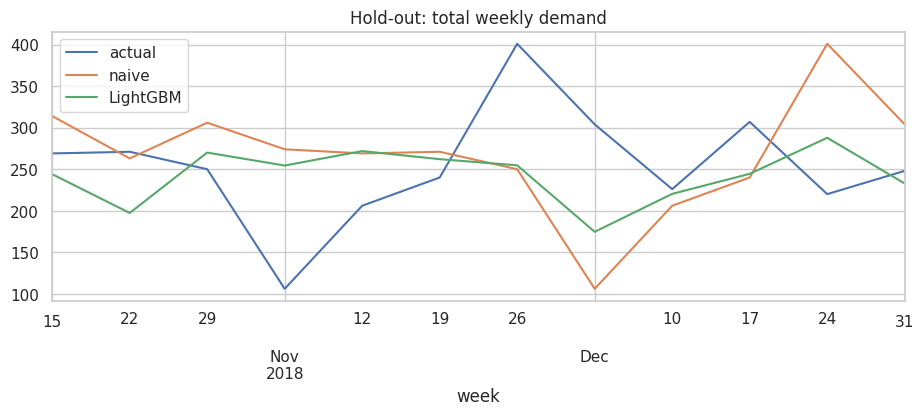

In [17]:
t = test.assign(pred=pred).groupby("week")[["demand", "lag_4", "pred"]].sum()
t.rename(columns={"demand":"actual","lag_4":"naive","pred":"LightGBM"}).plot(figsize=(11, 3.5), title="Hold-out: total weekly demand")

In [18]:
sel = test.assign(pred=pred).groupby("item").apply(lambda d: pd.Series({
    "actual": d.demand.sum(), "WAPE_model": (d.demand - d.pred).abs().sum() / max(d.demand.sum(), 1),
    "WAPE_naive": (d.demand - d.lag_4).abs().sum() / max(d.demand.sum(), 1)})).sort_values("actual", ascending=False)
sel.round(3).head(15)

,actual,WAPE_model,WAPE_naive
item,,,
engine oil,607.0,0.190,0.234
air filter,366.0,0.202,0.301
m oil,287.0,0.340,0.348
sprocket rubber,253.0,0.478,0.375
disc oil,234.0,0.383,0.410
sprocket bearing,211.0,0.453,0.393
oil filter,180.0,0.291,0.367
brake shoe,171.0,0.470,0.737
disc pad,91.0,0.559,0.549


## 5b. Time-series cross-validation
Rolling-origin folds over weeks (`TimeSeriesSplit`): the model is retrained on everything before each fold. Mean and std show how stable the gain over naive is.

In [19]:
cvt = P.cv(pd.concat([train, test]))
display(cvt.round(3))
cvt.drop(columns="test_from").agg(["mean", "std"]).round(3)

,test_from,WAPE_lightgbm,WAPE_naive,MAE_lightgbm,gain_overstock_events,gain_stockout_events,gain_overstock_units,gain_stockout_units
0,2018-04-02,0.267,0.343,1.695,0.113,0.014,0.380,0.072
1,2018-05-28,0.321,0.351,2.393,0.304,-0.241,0.575,-0.166
2,2018-07-23,0.383,0.447,3.020,0.151,-0.071,0.359,0.018
3,2018-09-17,0.434,0.457,4.457,0.375,-0.302,0.507,-0.428
4,2018-11-12,0.388,0.461,4.175,0.227,-0.102,0.614,-0.203


,WAPE_lightgbm,WAPE_naive,MAE_lightgbm,gain_overstock_events,gain_stockout_events,gain_overstock_units,gain_stockout_units
mean,0.359,0.412,3.148,0.234,-0.140,0.487,-0.141
std,0.065,0.059,1.169,0.108,0.129,0.114,0.199


## 5c. ARIMA (annual Fourier terms) and Prophet
Per-series classical models on the top 8 parts (centres summed), 4-week-ahead rolling origins over the hold-out weeks, compared with LightGBM and naive on the same rows. LSTM is not run: very short series, heavy dependencies, unlikely to beat boosting.

In [20]:
tp_ = test.assign(pred=pred)[["item", "centre", "week", "demand", "lag_4", "pred"]]
cmp_tab, _ = P.classical_compare(feat, last, tp_)
display(cmp_tab.round(3))
print("lowest WAPE:", cmp_tab.WAPE.idxmin())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,MAE,RMSE,WAPE
naive_lag4,7.469,10.724,0.367
lightgbm,6.360,8.491,0.313
arima_fourier,6.410,8.775,0.315
prophet,5.503,7.567,0.270


lowest WAPE: prophet


## 6. Feature importance

<Axes: title={'center': 'LightGBM gain importance'}>

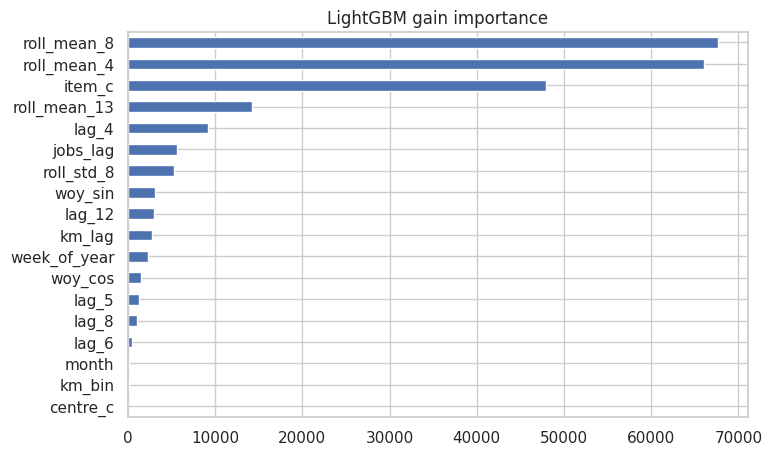

In [21]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=P.FEATURES).sort_values()
imp.plot.barh(figsize=(8, 5), title="LightGBM gain importance")

## 7. Final model, forecast and artifacts
Refits on all observed weeks, saves `models/demand_model.joblib`, `outputs/forecast.csv` (part_name x service_centre x week -> predicted_demand) and the other outputs.

In [22]:
m = P.run(df, CENTRE_COL, top_items=TOP_ITEMS, top_centres=TOP_CENTRES)
fc = pd.read_csv("outputs/forecast.csv", parse_dates=["week"])
display(fc.head(12))
fc.groupby("week").predicted_demand.sum().round(1)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,part_name,service_centre,week,predicted_demand
0,air filter,ALL,2019-01-07,28.99
1,air filter,ALL,2019-01-14,29.06
2,air filter,ALL,2019-01-21,30.89
3,air filter,ALL,2019-01-28,29.91
4,brake shoe,ALL,2019-01-07,10.62
5,brake shoe,ALL,2019-01-14,12.60
6,brake shoe,ALL,2019-01-21,11.46
7,brake shoe,ALL,2019-01-28,10.96
8,chain overhaul,ALL,2019-01-07,5.31
9,chain overhaul,ALL,2019-01-14,5.61


,predicted_demand
week,
2019-01-07,206.1
2019-01-14,222.2
2019-01-21,219.7
2019-01-28,223.4


<Axes: title={'center': 'Top 10 parts: forecast demand, next 4 weeks'}, ylabel='part_name'>

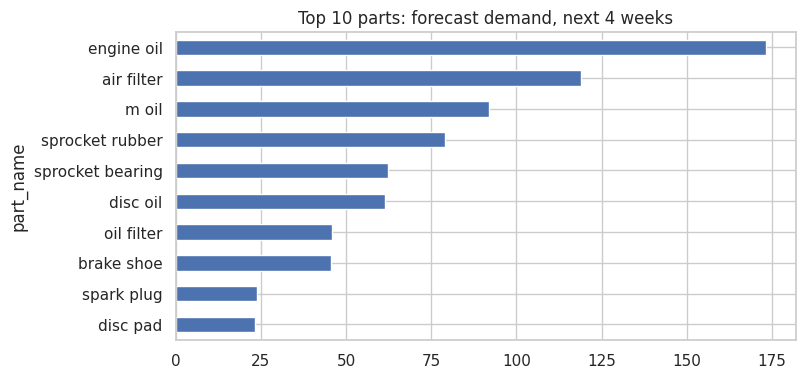

In [23]:
pn = fc.groupby("part_name").predicted_demand.sum().sort_values(ascending=False).head(10)
pn.sort_values().plot.barh(figsize=(8, 4), title="Top 10 parts: forecast demand, next 4 weeks")

## 8. Business recommendations (generated from the results above)

In [24]:
from IPython.display import Markdown
Markdown("\n".join(f"{i}. {r}" for i, r in enumerate(m["recommendations"], 1)))

1. Order first: engine oil (~173 lines in the next 4 weeks), air filter (~119 lines in the next 4 weeks), m oil (~92 lines in the next 4 weeks), sprocket rubber (~79 lines in the next 4 weeks), sprocket bearing (~62 lines in the next 4 weeks).
2. Target not met: events fell 11% (overstock) and -6% (stockout) versus naive, below 20% on at least one. Units fell 31% and -8%, so use the model for sizing orders and judge it on units, not event counts.
3. The model under-orders more than it over-orders (691 short vs 547 excess units on hold-out): add a safety-stock buffer on fast-moving parts.
4. Keep manual review for hard-to-forecast parts (hold-out WAPE above 60%): spark plug, clutch cable, clutch assembly, clutch cover gasket, clutch overhual.
5. Seasonal parts: stock up the month before the peak for sprocket rubber (peak month 12), sprocket bearing (peak month 12), drum bolt (peak month 9), seat cover (peak month 12).
6. Close the data gaps: record quantity, part number and service-centre ID on every invoice line. Demand is currently a count of lines, and services and parts share one text field.

**Limitations:** demand counts lines, not units; the centre dimension is a proxy; part names come from free text; LSTM not run (short series). See the README.

## 9. PDF report

In [25]:
!python report.py
try:
    from google.colab import files
    files.download("outputs/project_report.pdf"); files.download("outputs/forecast.csv")
except ImportError:
    pass

outputs/project_report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>